# ECE1512 Project A - Build an ABMIL training pipeline in PyTorch

This notebook uses pre-extracted whole-slide histopathology features and guides you through a complete PyTorch classification pipeline. The goal is not merely to run ABMIL; it is to understand the code path from data loading to optimization, validation, checkpoint selection, and final testing.

Please complete every cell marked `TODO`. Dataset engineering and metric boilerplate are provided so you can focus on the machine-learning training workflow.

This project requires basic familiarity with Python object-oriented programming (OOP). If you have limited experience with Python OOP, please review the provided introductory video before starting the project. 

[PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/introyt1_tutorial.html)

[Python Object-Oriented Programming ](https://www.youtube.com/watch?v=JeznW_7DlB0)

**Research extension:** Propose two research ideas and implement and evaluate one selected idea. Report ABMIL baseline and selected-extension results on **CAMELYON16, CAMELYON17, and BRACS**, using the same features and train/validation/test splits within each dataset. 


## Learning objectives

After this project you should be able to explain and implement:

1. `Dataset` vs. `DataLoader`, batching, shuffling.
2. `nn.Module`, trainable parameters, and `forward()`.
3. A classification loss and optimizer.
4. The training sequence `zero_grad -> forward -> loss -> backward -> step`.
5. The difference between `model.train()` and `model.eval()`.

## Step 0. Download Pre-extracted WSI Features & Select the Project Directory
Download the required feature file(s) from Zenodo or Hugging Face:

https://zenodo.org/records/23130543

https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature


Place the HDF5 file under the path expected by your YAML configuration in the `config/`, or edit data_dir in the YAML file.


In [ ]:
!pip install -q torchmetrics h5py pandas scikit-learn pyyaml matplotlib openslide-python openslide-bin


In [1]:
import os, sys, copy, time
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from utils import TODO


PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU


If you are using Google Colab with Drive, mount Drive first and change `PROJECT_DIR`.

In [2]:
# # Optional in Google Colab:
# from google.colab import drive
# drive.mount('/content/drive')

PROJECT_DIR = './'
DATASET = 'BRACS'  # Choose: 'C16', 'C17', or 'BRACS'

CONFIG_FILES = {
    'C16': 'camelyon16_medical_ssl_config.yml',
    'C17': 'camelyon17_medical_ssl_config.yml',
    'BRACS': 'bracs_medical_ssl_config.yml',
}
CONFIG_PATH = os.path.join(PROJECT_DIR, 'config', CONFIG_FILES[DATASET])

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print('Project:', os.path.abspath(PROJECT_DIR))
print('Config :', CONFIG_PATH)

from wsi_visualization import visualize_wsi_attention


Project: D:\ChromeDownload\1512\ProjectA\Project_A_Code
Config : ./config\bracs_medical_ssl_config.yml


In [37]:
from dataloader import build_HDF5_feat_dataset, mil_collate_fn
from utils import load_config, seed_everything, infer_feature_dim, classification_metrics

conf = load_config(CONFIG_PATH)
seed_everything(int(conf.seed))
print(conf)

if os.path.exists(conf.data_dir):
    print('Feature file exists:', os.path.exists(conf.data_dir), conf.data_dir)
else:
    print('\nDownload the required feature file from: https://zenodo.org/records/23130543')
    print('Then update data_dir in:', CONFIG_PATH)
    

Struct(B=1, D_attn=128, D_feat=384, D_inner=256, data_dir='./feature/BRACS/patch_feats_pretrain_medical_ssl.h5', dataset='BRACS', dataset_csv_dir='./dataset_csv', droprate=0.0, lr=0.0001, n_class=7, n_res=0, n_shot=0, n_worker=0, pin_memory=True, seed=42, train_epoch=30, warmup_epoch=3, wd=1e-05)
Feature file exists: True ./feature/BRACS/patch_feats_pretrain_medical_ssl.h5


# Step 1 - Dataset and DataLoader

`build_HDF5_feat_dataset` is provided. It creates train/validation/test `Dataset` objects without loading all slide features into memory at once.


Complete the three `DataLoader` definitions. Think about which split should be shuffled.

[Download WSI datasets](https://zenodo.org/records/23130543)

[Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)


[PyTorch DataLoader](https://docs.pytorch.org/docs/2.14/data.html#torch.utils.data.DataLoader)


[PyTorch Datasets](https://docs.pytorch.org/vision/stable/datasets.html)


In [38]:
train_data, val_data, test_data = build_HDF5_feat_dataset(conf.data_dir, conf)
conf.D_feat = infer_feature_dim(train_data)
print('Split sizes: Train {}, Validation {}, Test {};'.format(len(train_data), len(val_data), len(test_data)))
print("Feature Shape: {};".format(tuple(train_data[1]['input'].shape)))
print("Label: {}; \nSlide ID: {}.".format(train_data[1]['label'], train_data[1]['slide_id']))

Split sizes: Train 389, Validation 62, Test 86;
Feature Shape: (7540, 384);
Label: 1; 
Slide ID: BRACS_1003659.


In [39]:
batch_size=conf.B
num_workers=int(conf.n_worker)
pin_memory=bool(conf.pin_memory) and torch.cuda.is_available()
collate_fn=mil_collate_fn
print("DataLoader args: Batch size {}; \n \
      # CPUs {};  \n \
      pin_memory {};  \n \
      collate_fn {}".format(batch_size, num_workers, pin_memory, collate_fn))


DataLoader args: Batch size 1; 
       # CPUs 0;  
       pin_memory True;  
       collate_fn <function mil_collate_fn at 0x00000196FB806980>


In [40]:
# TODO 1A: create the training DataLoader. Training data should be shuffled.
train_loader = DataLoader(
    train_data,
    batch_size = batch_size,
    shuffle = True,
    num_workers = num_workers,
    pin_memory = pin_memory,
    collate_fn = collate_fn,
)

# TODO 1B: create validation and test DataLoaders. Do not shuffle them.
val_loader = DataLoader(
    val_data,
    batch_size = batch_size,
    shuffle = False,
    num_workers = num_workers,
    pin_memory = pin_memory,
    collate_fn = collate_fn,
)

test_loader = DataLoader(
    test_data,
    batch_size = batch_size,
    shuffle = False,
    num_workers = num_workers,
    pin_memory = pin_memory,
    collate_fn = collate_fn,
)

In [41]:
# Inspect one MIL batch.
batch = next(iter(train_loader))
print('input:', tuple(batch['input'].shape), batch['input'].dtype)
print('label:', tuple(batch['label'].shape), batch['label'].dtype)
print('slide IDs:', batch['slide_id'])

input: (1, 16307, 384) torch.float32
label: (1,) torch.int64
slide IDs: ['BRACS_1915']


**Questions for your report:**

- What is the difference between a `Dataset` and a `DataLoader`?
- Which Dataloader should use `shuffle=True`? Why?
- For a batch with input shape `[B, N, D]`, what do `B`, `N`, and `D` mean in this project?


# Step 2 - Implement the ABMIL model

For each patch feature $h_i$, the gated attention score follows Ilse et al. (2018):

$$
a_i = w^T\left[\tanh(Vh_i) \odot \sigma(Uh_i)\right].
$$

The attention logits are normalized over instances:

$$
\alpha_i = \frac{\exp(a_i)}{\sum_j \exp(a_j)},
$$

and the slide representation is

$$
z = \sum_i \alpha_i h_i.
$$

You will implement the learnable layers and the key `forward()` operations.

[Custom nn Modules](https://docs.pytorch.org/tutorials/beginner/examples_nn/polynomial_module.html)

[nn.Linear](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Linear.html)

[nn.modules.dropout](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Dropout.html)

[nn.ReLU](https://docs.pytorch.org/docs/2.14/generated/torch.nn.ReLU.html)

[torch.nn.functional.softmax (F.softmax)](https://docs.pytorch.org/docs/2.14/generated/torch.nn.functional.softmax.html)

[torch.bmm](https://docs.pytorch.org/docs/2.14/generated/torch.bmm.html)

In [3]:
class Classifier1FC(nn.Module):
    def __init__(self, n_channels, n_classes, droprate=0.0):
        super().__init__()
        self.dropout = nn.Dropout(droprate) if droprate > 0 else nn.Identity()
        # TODO 2A: one linear layer from n_channels to n_classes.
        self.fc = nn.Linear(n_channels, n_classes)

    def forward(self, x):
        # TODO 2B: apply dropout, then the classifier.
        return self.fc(self.dropout(x))


class DimReduction(nn.Module):
    def __init__(self, n_channels, m_dim):
        super().__init__()
        # TODO 2C: project patch features to m_dim and use ReLU.
        self.fc = nn.Linear(n_channels, m_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        # TODO 2D: linear projection followed by ReLU.
        return self.relu(self.fc(x))


class AttentionGated(nn.Module):
    def __init__(self, L=256, D=128, K=1):
        super().__init__()
        self.attention_V = nn.Sequential(nn.Linear(L, D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(L, D), nn.Sigmoid())
        self.attention_weights_w = nn.Linear(D, K)

    def forward(self, x):
        # x: [B, N, L]
        # TODO 2E: implement the two gated branches.
        a_v = self.attention_V(x)
        a_u = self.attention_U(x)

        a = self.attention_weights_w(a_v * a_u)
        return a.transpose(1, 2)


class ABMIL(nn.Module):
    def __init__(self, conf):
        super().__init__()
        self.dimreduction = DimReduction(conf.D_feat, conf.D_inner)
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=1)
        self.classifier = Classifier1FC(
            conf.D_inner, conf.n_class, conf.droprate
        )

    def forward(self, x, return_attention=False):
        # x: [B, N, D_feat]
        med_feat = self.dimreduction(x)       # [B, N, D_inner]
        a_logits = self.attention(med_feat)   # [B, 1, N]

        # TODO 2G: normalize attention logits over the instance dimension.
        attention = F.softmax(a_logits, dim=-1)

        # TODO 2H: weighted aggregation. torch.bmm is useful here.
        bag_feat = torch.bmm(attention, med_feat).squeeze(1)

        # TODO 2I: classify the slide representation.
        logits = self.classifier(bag_feat)

        if return_attention:
            return logits, attention
        return logits

**Sanity Check**

Before running the full training pipeline, check the tensor shapes and attention normalization.


In [43]:
model_cpu = ABMIL(conf).eval()

x_demo = torch.randn(2, 7, conf.D_feat)


with torch.no_grad():
    logits_demo, attn_demo = model_cpu(x_demo, return_attention=True)

print('logits:', logits_demo.shape)
print('attention:', attn_demo.shape)
print('attention sums:', attn_demo.sum(dim=-1))

assert logits_demo.shape == (2, int(conf.n_class))
assert attn_demo.shape == (2, 1, 7)
torch.testing.assert_close(attn_demo.sum(dim=-1), torch.ones(2, 1))
print('Sanity check passed.')


logits: torch.Size([2, 7])
attention: torch.Size([2, 1, 7])
attention sums: tensor([[1.],
        [1.]])
Sanity check passed.


**Questions:**

- Which tensors in your model contain trainable parameters?
- What properties do attention weights have after softmax?
- Could we replace softmax with another function?


# Step 3 - Device, loss, and optimizer

For multi-class slide classification, use cross-entropy as the baseline objective and AdamW as the baseline optimizer. Complete the code below.

[nn.CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html)

[torch.optim.AdamW](https://docs.pytorch.org/docs/2.14/generated/torch.optim.AdamW.html)

In [44]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ABMIL(conf).to(device)

# TODO 3A: define the multi-class classification loss.
criterion = nn.CrossEntropyLoss()

# TODO 3B: create AdamW and pass the model parameters, learning rate, and weight decay.
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr = conf.lr,
    weight_decay = conf.wd,
)

print('Device:', device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

Device: cuda
Trainable parameters: 166280


# Step 4 - Complete one training epoch

The essential PyTorch optimization sequence is:

`model.train()` -> move tensors to device -> `zero_grad()` -> forward pass -> compute loss -> `backward()` -> `step()`.

Implement this sequence yourself. This is one of the main learning objectives of the project.

[Training with PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html)

[train() vs eval()](https://discuss.pytorch.org/t/model-train-and-model-eval-vs-model-and-model-eval/5744)

In [45]:
def train_one_epoch(model, criterion, data_loader, optimizer, device):
    # TODO 4A: put the model in training mode.
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for data in data_loader:
        # TODO 4B: move input and labels to the selected device.
        bag = data["input"].to(device, dtype = torch.float32)
        labels = data["label"].to(device, dtype = torch.long)

        # TODO 4C: clear gradients from the previous iteration.
        optimizer.zero_grad()

        # TODO 4D: forward pass.
        logits = model(bag)

        # TODO 4E: compute the loss.
        loss = criterion(logits, labels)

        # TODO 4F: back-propagate gradients.
        loss.backward()

        # TODO 4G: update the model parameters.
        optimizer.step()

        batch_size = labels.shape[0]
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    return {
        'loss': total_loss / total_examples,
        'acc': 100.0 * total_correct / total_examples,
    }

# Step 5 - Validation and test evaluation

Evaluation should not update the model. Complete the missing lines and use the provided metric helper for macro-AUROC and macro-F1.


In [57]:
@torch.no_grad()
def evaluate(model, criterion, data_loader, device, conf):
    # TODO 5A: switch to evaluation mode.
    model.eval()

    total_loss = 0.0
    total_examples = 0
    probabilities_all = []
    labels_all = []

    for data in data_loader:
        # TODO 5B: move data to device.
        bag = data["input"].to(device, dtype = torch.float32)
        labels = data["label"].to(device, dtype = torch.long)

        # TODO 5C: forward pass and loss.
        logits = model(bag)
        loss = criterion(logits, labels)

        # TODO 5D: convert class logits into probabilities.
        probabilities = F.softmax(logits, dim = 1)

        total_loss += loss.item() * labels.shape[0]
        total_examples += labels.shape[0]
        probabilities_all.append(probabilities)
        labels_all.append(labels)

    probabilities_all = torch.cat(probabilities_all, dim=0)
    labels_all = torch.cat(labels_all, dim=0)
    metrics = classification_metrics(probabilities_all, labels_all, conf.n_class)
    metrics['loss'] = total_loss / total_examples
    return metrics

**Checkpoint questions:**

- Why are `model.eval()` and `torch.no_grad()` different concepts?
- What would happen if gradients were accumulated because `optimizer.zero_grad()` was omitted?
- Why must the test set not be used to choose the best epoch?


# Step 6 - Train, validate, and select the best checkpoint

Use the validation set to choose the best epoch. The test set must remain untouched until model selection is complete.

For debugging, set `NUM_EPOCHS = 2`. For your reported baseline, use the full configured epoch count unless instructed otherwise.


In [47]:
# Use JSON and tables to save the experiment results
import json
import pandas as pd

# Create a separate folder so different runs do not overwrite each other
run_dir = Path("results") / "ABMIL" / f"{DATASET}_seed{conf.seed}"
run_dir.mkdir(parents = True, exist_ok = False)

# Save the settings so we can load the same model setup later
with open(run_dir / "config.json", "w", encoding = "utf-8") as f:
    json.dump(vars(conf), f, indent = 2)

# Save the slide lists so later experiments use the same data splits
with open(run_dir / "splits.json", "w", encoding = "utf-8") as f:
    json.dump(
        {
            "train": list(train_data.data_names),
            "validation": list(val_data.data_names),
            "test": list(test_data.data_names),
        },
        f,
        indent = 2,
    )

# Reset the seed so model initialization can be repeated
seed_everything(int(conf.seed))

# Create a fresh model so earlier checks do not affect this training run
model = ABMIL(conf).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr = conf.lr,
    weight_decay = conf.wd,
)

NUM_EPOCHS = int(conf.train_epoch)  # You may temporarily set this to 2 while debugging

best_score = float('-inf')
best_epoch = -1
best_model_state = None
history = []

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_metrics = train_one_epoch(model, criterion, train_loader, optimizer, device)
    val_metrics = evaluate(model, criterion, val_loader, device, conf)

    # Baseline selection criterion: macro-AUROC + macro-F1
    score = val_metrics['auc'] + val_metrics['f1']

    if score > best_score:
        best_score = score
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())

        # Save the best model so later cells can load it again
        torch.save(
            {
                "model_state_dict": {
                    key: value.detach().cpu().clone()
                    for key, value in best_model_state.items()
                },
                "best_epoch": best_epoch + 1,
                "best_score": float(best_score),
                "config": vars(conf),
            },
            run_dir / "best_model.pt",
        )
    row = {
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'train_acc': train_metrics['acc'],
        'val_loss': val_metrics['loss'],
        'val_acc': val_metrics['acc'],
        'val_auc': val_metrics['auc'],
        'val_f1': val_metrics['f1'],
    }
    history.append(row)

    # Save the epoch results so we can check training progress later
    pd.DataFrame(history).to_csv(
        run_dir / "history.csv", index = False
    )

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
          f"train loss={row['train_loss']:.4f} acc={row['train_acc']:.2f} | "
          f"val loss={row['val_loss']:.4f} auc={row['val_auc']:.3f} f1={row['val_f1']:.3f} | "
          f"best={best_epoch+1} | {time.time()-start:.1f}s")

assert best_model_state is not None

# Save a short record so we can check how this run was trained
with open(
    run_dir / "training_summary.json",
    "w",
    encoding = "utf-8",
) as f:
    json.dump(
        {
            "dataset": DATASET,
            "method": "ABMIL",
            "seed": int(conf.seed),
            "epochs": NUM_EPOCHS,
            "best_epoch": best_epoch + 1,
            "best_validation_score": float(best_score),
            "selection_criterion": "validation macro-AUROC + macro-F1",
            "torch_version": str(torch.__version__),
            "cuda_runtime": torch.version.cuda,
        },
        f,
        indent = 2,
    )

# Print the result folder so we can find the saved files
print("\nTraining complete.")
print("Best validation epoch:", best_epoch + 1)
print("Results saved to:", run_dir)

Epoch 01/30 | train loss=1.6019 acc=41.39 | val loss=1.8187 auc=0.683 f1=0.192 | best=1 | 9.4s
Epoch 02/30 | train loss=1.2425 acc=54.50 | val loss=1.7573 auc=0.744 f1=0.134 | best=2 | 7.7s
Epoch 03/30 | train loss=1.0570 acc=61.44 | val loss=1.4000 auc=0.807 f1=0.443 | best=3 | 7.8s
Epoch 04/30 | train loss=0.9259 acc=65.30 | val loss=1.3701 auc=0.822 f1=0.361 | best=3 | 7.8s
Epoch 05/30 | train loss=0.8610 acc=68.38 | val loss=1.4274 auc=0.822 f1=0.363 | best=3 | 7.2s
Epoch 06/30 | train loss=0.8019 acc=70.69 | val loss=1.4912 auc=0.824 f1=0.346 | best=3 | 7.1s
Epoch 07/30 | train loss=0.7543 acc=71.98 | val loss=1.5263 auc=0.828 f1=0.369 | best=3 | 7.1s
Epoch 08/30 | train loss=0.7198 acc=73.01 | val loss=1.5492 auc=0.814 f1=0.338 | best=3 | 7.2s
Epoch 09/30 | train loss=0.6736 acc=76.61 | val loss=1.5014 auc=0.814 f1=0.358 | best=3 | 7.1s
Epoch 10/30 | train loss=0.6375 acc=75.32 | val loss=1.5338 auc=0.826 f1=0.378 | best=3 | 7.1s
Epoch 11/30 | train loss=0.6175 acc=77.63 | val lo

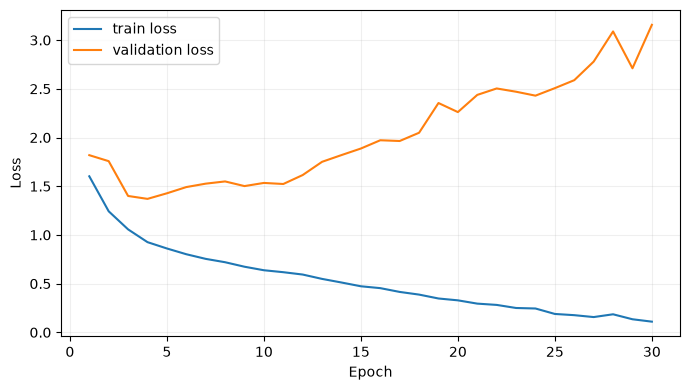

In [48]:
# Plot learning curves
epochs = [x['epoch'] + 1 for x in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [x['train_loss'] for x in history], label='train loss')
plt.plot(epochs, [x['val_loss'] for x in history], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.2)

# Adjust the spacing so the labels fit inside the figure
plt.tight_layout()

# Save the curves so we can use them in the report
plt.savefig(run_dir / "loss_curves.png", dpi = 300)

plt.show()

# Step 7 - Final held-out test evaluation

Only now, after the best checkpoint has been chosen from validation performance, load it and evaluate once on the test set.


In [49]:
model.load_state_dict(best_model_state)
test_metrics = evaluate(model, criterion, test_loader, device, conf)

print('Best validation epoch:', best_epoch + 1)
print('Final test metrics:')
for key, value in test_metrics.items():
    print(f'  {key}: {value:.4f}')

# Save the test results so later experiments can check the baseline
with open(
    run_dir / "test_metrics.json",
    "w",
    encoding = "utf-8",
) as f:
    json.dump(
        {
            "dataset": DATASET,
            "method": "ABMIL",
            "seed": int(conf.seed),
            "best_epoch": best_epoch + 1,
            "test_slides": len(test_data),
            "metrics": {
                key: float(value)
                for key, value in test_metrics.items()
            },
        },
        f,
        indent = 2,
    )

# Print the file path so we can find the saved test results
print('Test results saved to:', run_dir / "test_metrics.json")

Best validation epoch: 3
Final test metrics:
  auc: 0.7858
  acc: 46.5116
  f1: 0.3716
  loss: 1.4110
Test results saved to: results\ABMIL\BRACS_seed42\test_metrics.json


# Step 8 -  Inspect Attention on One Slide

Attention is useful for understanding which instances contribute strongly to the learned bag representation, but attention weights should not automatically be interpreted as causal explanations.


In [63]:
# Load C16 separately so earlier dataset choices do not affect this check
import json
from utils import Struct
from dataloader import HDF5FeatureDataset, mil_collate_fn

attention_run_dir = (
    Path(PROJECT_DIR) / "results" / "ABMIL" / "C16_seed42"
)

# Read the saved settings so the model uses the correct C16 setup
with open(
    attention_run_dir / "config.json",
    encoding = "utf-8",
) as f:
    attention_conf = Struct(**json.load(f))

# Read the saved split so we inspect a C16 test slide
with open(
    attention_run_dir / "splits.json",
    encoding = "utf-8",
) as f:
    attention_splits = json.load(f)

# Load the best C16 weights so we inspect the selected model
attention_checkpoint = torch.load(
    attention_run_dir / "best_model.pt",
    map_location = "cpu",
    weights_only = True,
)

attention_best_state = attention_checkpoint["model_state_dict"]

attention_model = ABMIL(attention_conf).to(device)
attention_model.load_state_dict(attention_best_state)

# Rebuild the test dataset so we use the saved C16 test split
attention_test_data = HDF5FeatureDataset(
    attention_conf.data_dir,
    attention_splits["test"],
    attention_conf,
)

one_batch = mil_collate_fn([attention_test_data[0]])
attention_model.eval()
with torch.no_grad():
    logits, attention = attention_model(
        one_batch['input'].to(device, dtype=torch.float32),
        return_attention=True,
    )

# Print the dataset name so we can check that C16 is loaded
print("Attention dataset:", attention_conf.dataset)
print('Slide:', one_batch['slide_id'][0])
print('Predicted class:', int(logits.argmax(dim=1)[0]))
print('Attention shape:', tuple(attention.shape))
print('Attention sum for first slide:', float(attention[0].sum()))

Attention dataset: CAMELYON16
Slide: test_001
Predicted class: 1
Attention shape: (1, 1, 17294)
Attention sum for first slide: 1.0


## Visualize Attention on Whole-Slide Images (WSIs)

Before running the attention visualization, please complete the following steps:

1. Visit the [ECE1512-WSI-Feature dataset on Hugging Face](https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature)

2. Download the original WSIs `test_067.tif` and `test_068.tif` and the corresponding tumor annotation file `test_068.xml`.

3. Create a folder named `slide/` under your project directory and place the downloaded files in this folder.

The Step 8 cells load the saved CAMELYON16 baseline checkpoint,
configuration, and test split from results/ABMIL/C16_seed42.
Attention inspection therefore uses the C16 model regardless of
the DATASET selected earlier in the notebook. The two slides
below are read from PROJECT_DIR/slide:

- **test_068 (tumor):** attention overlay and green contours from `test_068.xml`, including a zoom of the annotated region.
- **test_067 (normal):** attention overlay without annotation contours, including a zoom around the highest-attention patch.

The blue rectangle marks the zoom shown on the right. Colors show **attention percentiles within each slide**, not patch tumor probabilities; areas without extracted patches stay transparent. The displayed `P(tumor)` is the model's slide-level prediction.

HDF5 patch coordinates and XML contour coordinates are assumed to be expressed in level-0 `(x, y)`  coordinates; patch coordinates are treated as top-left corners. The function parameter `patch_size_level0=512` is an editable **assumption** for the patch footprint because these HDF5 files do not store patch-size metadata. Match it to the feature extractor's patch size for an exact footprint. All visualization functions are in `wsi_visualization.py`; the cell below only calls `visualize_wsi_attention`.

[OpenSlide Python](https://openslide.org/api/python/) reads a thumbnail and a pyramid-level crop rather than loading the full-resolution WSI into memory. If dependencies are missing, run `%pip install openslide-python openslide-bin` and restart the kernel if needed. Raw per-patch attention and coordinates are retained in `attention_visualizations`.


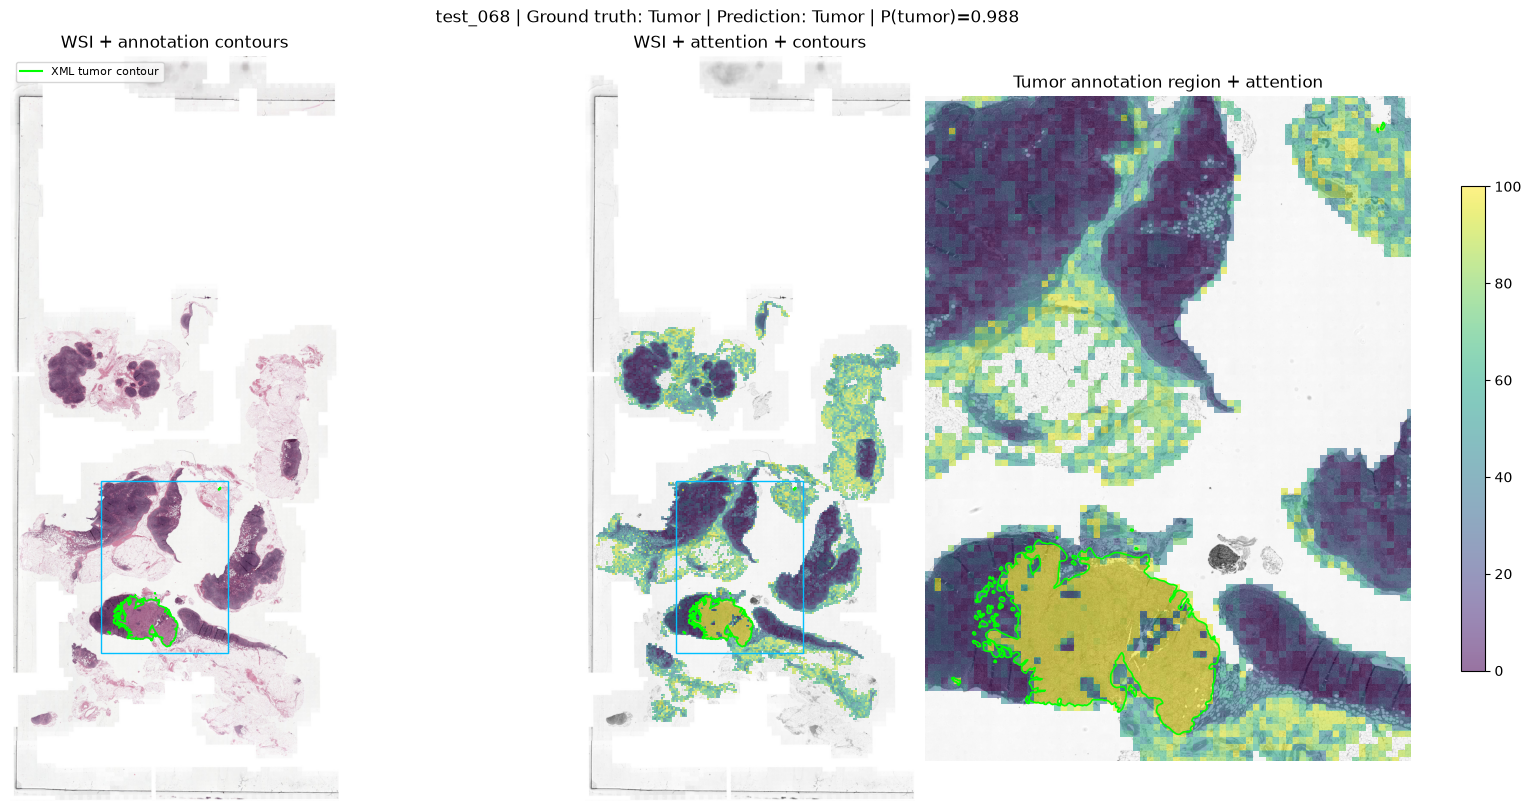

test_068: 15,037 patches; attention sum=1.000000; 45 annotation contours


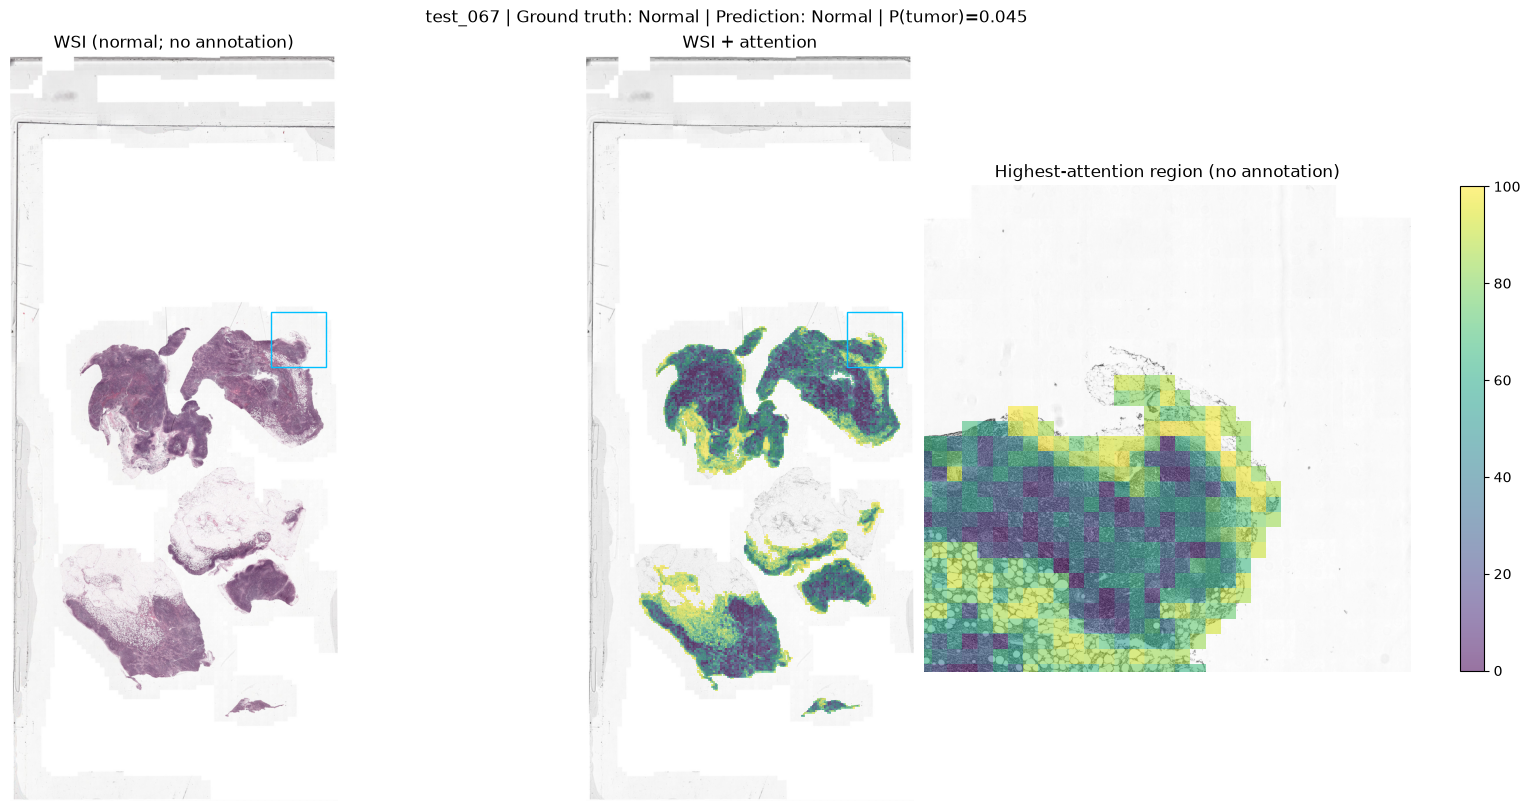

test_067: 11,926 patches; attention sum=1.000000; 0 annotation contours (no XML available)


In [64]:
import importlib
import wsi_visualization

# Reload the helper so Python uses the updated image-saving code
importlib.reload(wsi_visualization)

# Use the saved C16 model so the heatmaps match the C16 baseline
# Save the figures so we can use them in the report
attention_visualizations = wsi_visualization.visualize_wsi_attention(
    attention_model,
    attention_conf,
    PROJECT_DIR,
    attention_best_state,
    output_dir = attention_run_dir,
)

# Step 9 - Research extension: propose two ideas, implement one of them

After completing the ABMIL baseline, propose **two distinct research ideas**. Select **one** for implementation and evaluation on **CAMELYON16 (C16), CAMELYON17 (C17), and BRACS**. You may explore explainability, more advanced model structures, improved objectives beyond cross-entropy, or another well-motivated direction.

**A negative result will not be penalized if the design choices, experiments, observations, and possible reasons for failure are well justified.** Report evidence relevant to your hypothesis: an explainability idea, for example, needs an explanation evaluation in addition to classification results.

Feel free to contact your TA to discuss your research ideas.

## Research Proposals

### Proposal 1: Faithfulness of Patch-Level Explanations

**Research Question**

Do patches with high attention have a strong effect on the model’s prediction?

**Motivation**

An attention map shows which patches receive higher weights. However, a high weight does not directly tell me which class a patch supports. I want to check how these patches affect the prediction.

**Proposed Method**

I plan to compare two ways of ranking patches. One uses attention weights alone. The other combines attention with class-specific information from the trained classifier.

I will use each dataset’s saved baseline model. For each slide, I will keep the original predicted class as the target class throughout the tests.

**Evaluation**

The deletion test will remove the top-ranked patches and run the model again. The retention test will keep only the top-ranked patches and run the model again.

I plan to test patch fractions of 5%, 10%, 20%, and 40%. Both ranking methods will use the same patch fractions. I will also repeat random patch selection as a comparison.

I will compare the changes in the target class probability on C16, C17, and BRACS. A useful ranking should identify patches whose removal lowers this probability. Keeping these patches should also help maintain the prediction.

This proposal is not implemented in this project.

### Proposal 2: Post-Hoc Confidence Calibration

**Research Question**

Can temperature scaling make the model’s confidence closer to its actual accuracy while keeping its predicted classes unchanged?

**Motivation**

Accuracy tells me how many slides the model classifies correctly. It does not tell me whether the model’s confidence is reasonable.

For example, a group of predictions may have an average confidence of 95%. If only 80% of them are correct, the model is too confident.

**Implemented Method**

I load each dataset’s best ABMIL checkpoint and freeze its parameters. I then fit one positive temperature, T, using the validation logits and labels. The fitting process minimizes validation cross-entropy, which is also NLL in this setting.

The code divides the logits by T before applying softmax. A temperature above 1 makes the probabilities less concentrated. A temperature below 1 makes them more concentrated. A positive temperature keeps the predicted class unchanged.

The test labels are not used to fit or select T.

**Evaluation**

I compare the original and calibrated predictions on C16, C17, and BRACS. Both versions use the same features, data splits, baseline checkpoints, and test slides.

I report accuracy, macro-AUROC, and macro-F1. I also report NLL, Brier score, ECE, and reliability diagrams to check the predicted probabilities.

**Metric Definitions**

NLL gives a larger penalty when the model assigns a low probability to the true class.

Brier score compares all class probabilities with the true labels. The code sums the squared errors across classes and then averages them across slides. It does not divide the result by the number of classes.

ECE compares average confidence with accuracy within confidence bins. The code uses five equal-width bins. The saved ECE values use a scale from 0 to 1. The figures and report show ECE as a percentage.

Lower NLL, Brier score, and ECE are better.

**Limitations**

The validation sets are small. They are also used for both checkpoint selection and temperature fitting.

C17 has shared patients between its training and validation sets. Its test slides come from different centers. These differences may affect the calibration results.

A lower validation NLL does not guarantee better calibration on the test set.

**Reference**

Guo et al., “On Calibration of Modern Neural Networks,” ICML 2017.

https://proceedings.mlr.press/v70/guo17a.html

In [4]:
# Step 9.1 - Shared functions for calibration experiments
import math
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path
from torch.utils.data import DataLoader

from dataloader import HDF5FeatureDataset, mil_collate_fn
from utils import Struct, classification_metrics


# Collect model scores, true labels, and slide IDs
@torch.no_grad()
def collect_logits(model, data_loader):
    # Use evaluation mode and keep inputs on the same device as the model
    model.eval()
    device = next(model.parameters()).device
    logits_all = []
    labels_all = []
    slide_ids = []

    for data in data_loader:
        bag = data["input"].to(device, dtype = torch.float32)

        # Collect raw class scores before softmax
        logits = model(bag)

        # Move the results to CPU and store scores in double precision
        logits_all.append(logits.detach().cpu().double())
        labels_all.append(data["label"].detach().cpu().long())
        slide_ids.extend(data["slide_id"])

    if not logits_all:
        raise ValueError("The data loader contains no slides.")

    logits = torch.cat(logits_all, dim = 0)
    labels = torch.cat(labels_all, dim = 0)

    # Check that the scores are finite and all result counts match
    assert torch.isfinite(logits).all().item()
    assert logits.shape[0] == labels.shape[0] == len(slide_ids)

    return logits, labels, slide_ids


# Use validation data to find a temperature that lowers NLL
def fit_temperature(val_logits, val_labels):
    # Use only validation predictions and labels here
    val_logits = val_logits.detach().cpu().double()
    val_labels = val_labels.detach().cpu().long()

    # Start with log temperature zero, which gives temperature one
    log_temperature = torch.nn.Parameter(
        torch.zeros((), dtype = torch.float64)
    )

    # Update only the temperature and leave the ABMIL weights unchanged
    optimizer = torch.optim.LBFGS(
        [log_temperature],
        lr = 0.1,
        max_iter = 100,
        line_search_fn = "strong_wolfe",
    )

    # Keep the temperature between 0.01 and 100
    log_limit = math.log(100.0)
    nll_before = F.cross_entropy(val_logits, val_labels).item()

    # Keep the original result as a candidate
    best_temperature = 1.0
    best_nll = nll_before

    # Calculate the loss and gradient for the current temperature
    def closure():
        nonlocal best_temperature, best_nll
        optimizer.zero_grad()

        # Convert log temperature to a positive temperature
        temperature = log_temperature.clamp(
            -log_limit, log_limit
        ).exp()

        # Calculate validation NLL using the scaled scores
        loss = F.cross_entropy(
            val_logits / temperature, val_labels
        )

        if not torch.isfinite(loss).item():
            raise ValueError("Non-finite validation calibration loss.")

        # Keep the temperature with the lowest validation NLL
        if loss.item() < best_nll:
            best_nll = loss.item()
            best_temperature = temperature.detach().item()

        # Calculate the gradient needed to adjust the temperature
        loss.backward()
        return loss

    optimizer.step(closure)

    return best_temperature, nll_before, best_nll


# Calculate classification and calibration metrics at the given temperature
@torch.no_grad()
def calibration_metrics(logits, labels, temperature = 1.0, n_bins = 5):
    if not math.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperature must be finite and positive.")

    logits = logits.detach().cpu().double()
    labels = labels.detach().cpu().long()

    # Apply the same temperature to every class score
    scaled_logits = logits / temperature
    probabilities = F.softmax(scaled_logits, dim = 1)

    # Check that the probabilities are finite and each row sums to one
    assert torch.isfinite(probabilities).all().item()

    torch.testing.assert_close(
        probabilities.sum(dim = 1),
        torch.ones(len(labels), dtype = torch.float64),
    )

    # Use the highest class probability as the prediction confidence
    confidence, predictions = probabilities.max(dim = 1)
    correct = predictions.eq(labels).double()

    # Mark the true class with one and the other classes with zero
    targets = F.one_hot(
        labels, num_classes = logits.shape[1]
    ).double()

    metrics = classification_metrics(
        probabilities.float(), labels, logits.shape[1]
    )

    # Use stable scores to calculate AUROC
    from sklearn.metrics import roc_auc_score

    if logits.shape[1] == 2:
        # Use the difference between the two class scores for binary AUROC
        scores = scaled_logits[:, 1] - scaled_logits[:, 0]

        metrics["auc"] = float(
            roc_auc_score(labels.numpy(), scores.numpy())
        )
    else:
        # Calculate one AUROC for each class and take the mean
        class_aucs = []

        for class_index in range(logits.shape[1]):
            other_classes = [
                index for index in range(logits.shape[1])
                if index != class_index
            ]

            scores = (
                scaled_logits[:, class_index]
                - torch.logsumexp(
                    scaled_logits[:, other_classes], dim = 1
                )
            )

            class_aucs.append(
                roc_auc_score(
                    labels.eq(class_index).numpy(),
                    scores.numpy(),
                )
            )

        metrics["auc"] = float(np.mean(class_aucs))

    # Calculate NLL from the scaled scores and true labels
    metrics["nll"] = F.cross_entropy(
        scaled_logits, labels
    ).item()

    # Calculate the Brier score using all class probabilities
    metrics["brier"] = (
        (probabilities - targets).square().sum(dim = 1).mean().item()
    )

    # Divide the confidence range into equal-width bins
    bin_edges = torch.linspace(
        0, 1, n_bins + 1, dtype = torch.float64
    )

    bins = []
    ece = 0.0

    for index in range(n_bins):
        lower = bin_edges[index]
        upper = bin_edges[index + 1]

        # Include zero in the first bin and avoid counting any value twice
        if index == 0:
            mask = (confidence >= lower) & (confidence <= upper)
        else:
            mask = (confidence > lower) & (confidence <= upper)

        count = int(mask.sum().item())
        accuracy = correct[mask].mean().item() if count else None
        mean_confidence = confidence[mask].mean().item() if count else None

        # Weight each confidence gap by the fraction of slides in that bin
        if count:
            ece += count / len(labels) * abs(
                accuracy - mean_confidence
            )

        # Keep empty bins in the table for consistent plots
        bins.append({
            "bin": index + 1,
            "lower": lower.item(),
            "upper": upper.item(),
            "count": count,
            "accuracy": accuracy,
            "confidence": mean_confidence,
        })

    metrics["ece"] = ece

    assert sum(row["count"] for row in bins) == len(labels)

    return metrics, bins


print("Calibration helper functions defined.")

Calibration helper functions defined.


In [5]:
# Step 9.2 - Calibration sanity checks on synthetic predictions

# Create five predictions with 95% confidence and 80% accuracy
synthetic_probabilities = torch.tensor(
    [
        [0.95, 0.05],
        [0.95, 0.05],
        [0.05, 0.95],
        [0.05, 0.95],
        [0.05, 0.95],
    ],
    dtype = torch.float64,
)

# Convert the probabilities to scores that softmax can recover
synthetic_logits = synthetic_probabilities.log()
synthetic_labels = torch.tensor([0, 0, 1, 1, 0])

# Fit the temperature using this small example
temperature, nll_before, nll_after = fit_temperature(
    synthetic_logits, synthetic_labels
)

# Compare the metrics before and after scaling
before_metrics, _ = calibration_metrics(
    synthetic_logits, synthetic_labels
)

after_metrics, _ = calibration_metrics(
    synthetic_logits, synthetic_labels, temperature
)

# Check that the temperature is positive and the fitted NLL does not increase
assert temperature > 0
assert nll_after <= nll_before + 1e-10

# Check that scaling does not change the predicted classes
assert torch.equal(
    synthetic_logits.argmax(dim = 1),
    (synthetic_logits / temperature).argmax(dim = 1),
)

# Check the known starting metrics and the lower ECE in this example
assert abs(before_metrics["acc"] - 80.0) < 1e-4
assert abs(before_metrics["ece"] - 0.15) < 1e-6
assert abs(after_metrics["acc"] - before_metrics["acc"]) < 1e-6
assert after_metrics["ece"] < before_metrics["ece"]

print(f"Synthetic temperature: {temperature:.4f}")
print(f"Synthetic NLL: {nll_before:.4f} -> {nll_after:.4f}")

print(
    f"Synthetic ECE: {before_metrics['ece']:.4f} -> "
    f"{after_metrics['ece']:.4f}"
)

print("Calibration sanity checks passed.")

Synthetic temperature: 2.1240
Synthetic NLL: 0.6402 -> 0.5004
Synthetic ECE: 0.1500 -> 0.0000
Calibration sanity checks passed.


In [6]:
# Step 9.3 - Temperature scaling on the three saved baselines
calibration_root = Path(PROJECT_DIR) / "results" / "TemperatureScaling"

calibration_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

calibration_datasets = ["C16", "C17", "BRACS"]
calibration_seed = 42
calibration_rows = []

assert "ABMIL" in globals(), "Run the Step 2 model-definition cell first."

# Check the output folders before running the experiments
for dataset_name in calibration_datasets:
    output_dir = (
        calibration_root / f"{dataset_name}_seed{calibration_seed}"
    )

    if output_dir.exists():
        raise FileExistsError(f"Results already exist: {output_dir}")

# Fit and evaluate a separate temperature for each dataset
for dataset_name in calibration_datasets:
    print(f"\n===== {dataset_name} =====", flush = True)

    baseline_dir = (
        Path(PROJECT_DIR) / "results" / "ABMIL"
        / f"{dataset_name}_seed{calibration_seed}"
    )

    output_dir = (
        calibration_root / f"{dataset_name}_seed{calibration_seed}"
    )

    # Read the settings and data splits saved with the baseline
    with open(baseline_dir / "config.json", encoding = "utf-8") as f:
        calibration_conf = Struct(**json.load(f))

    with open(baseline_dir / "splits.json", encoding = "utf-8") as f:
        saved_splits = json.load(f)

    with open(baseline_dir / "test_metrics.json", encoding = "utf-8") as f:
        saved_test_results = json.load(f)

    assert int(calibration_conf.B) == 1
    assert int(calibration_conf.seed) == calibration_seed

    # Rebuild the validation and test datasets using the saved slide lists
    validation_data = HDF5FeatureDataset(
        calibration_conf.data_dir,
        saved_splits["validation"],
        calibration_conf,
    )

    heldout_data = HDF5FeatureDataset(
        calibration_conf.data_dir,
        saved_splits["test"],
        calibration_conf,
    )

    # Keep the saved slide order by turning shuffle off
    validation_loader = DataLoader(
        validation_data,
        batch_size = 1,
        shuffle = False,
        num_workers = 0,
        collate_fn = mil_collate_fn,
    )

    heldout_loader = DataLoader(
        heldout_data,
        batch_size = 1,
        shuffle = False,
        num_workers = 0,
        collate_fn = mil_collate_fn,
    )

    # Load the best ABMIL model and freeze its parameters
    checkpoint = torch.load(
        baseline_dir / "best_model.pt",
        map_location = "cpu",
        weights_only = True,
    )

    assert checkpoint["best_epoch"] == saved_test_results["best_epoch"]

    calibration_model = ABMIL(calibration_conf).to(calibration_device)
    calibration_model.load_state_dict(checkpoint["model_state_dict"])
    calibration_model.requires_grad_(False)

    print("Collecting validation predictions ...", flush = True)

    val_logits, val_labels, val_ids = collect_logits(
        calibration_model, validation_loader
    )

    assert val_ids == saved_splits["validation"]

    # Fit the temperature before collecting test predictions
    temperature, val_nll_before, val_nll_after = fit_temperature(
        val_logits, val_labels
    )

    assert val_nll_after <= val_nll_before + 1e-10

    print(f"Temperature: {temperature:.4f}", flush = True)
    print("Evaluating held-out test predictions ...", flush = True)

    # Use the test set only after the temperature has been selected
    test_logits, test_labels, test_ids = collect_logits(
        calibration_model, heldout_loader
    )

    assert test_ids == saved_splits["test"]

    # Compare the test metrics with temperature one and the fitted temperature
    before_metrics, before_bins = calibration_metrics(
        test_logits, test_labels, temperature = 1.0
    )

    after_metrics, after_bins = calibration_metrics(
        test_logits, test_labels, temperature = temperature
    )

    # Check that the loaded model matches the saved baseline
    for metric in ["acc", "auc", "f1"]:
        difference = abs(
            before_metrics[metric]
            - saved_test_results["metrics"][metric]
        )

        assert difference < 1e-3, f"Baseline mismatch: {metric}"

    assert abs(
        before_metrics["nll"]
        - saved_test_results["metrics"]["loss"]
    ) < 1e-5

    before_probabilities = F.softmax(test_logits, dim = 1)

    after_probabilities = F.softmax(
        test_logits / temperature, dim = 1
    )

    before_predictions = before_probabilities.argmax(dim = 1)
    after_predictions = after_probabilities.argmax(dim = 1)

    # Confirm that scaling changes probabilities without changing predicted classes
    assert torch.equal(before_predictions, after_predictions)

    output_dir.mkdir(parents = True, exist_ok = False)

    # Save the settings, fitted temperature, metrics, and known limitations
    experiment = {
        "dataset": dataset_name,
        "seed": calibration_seed,
        "method": "TemperatureScaling",
        "baseline_best_epoch": checkpoint["best_epoch"],
        "temperature": temperature,
        "temperature_bounds": [0.01, 100.0],
        "fit_objective": "validation NLL",
        "validation_slides": len(validation_data),
        "test_slides": len(heldout_data),
        "validation_nll_before": val_nll_before,
        "validation_nll_after": val_nll_after,
        "ece_bins": 5,
        "brier_definition": "mean sum of squared errors across classes",
        "before": before_metrics,
        "after": after_metrics,
        "baseline_config": vars(calibration_conf),
        "limitations": [
            "Small validation sets.",
            "Validation data reused after checkpoint selection.",
            "C17 train/validation patient overlap and center-based test split.",
        ],
    }

    with open(
        output_dir / "experiment.json",
        "w",
        encoding = "utf-8",
    ) as f:
        json.dump(experiment, f, indent = 2, allow_nan = False)

    # Save model scores for later analysis
    np.savez_compressed(
        output_dir / "logits.npz",
        validation_logits = val_logits.numpy(),
        validation_labels = val_labels.numpy(),
        validation_slide_ids = np.asarray(val_ids),
        test_logits = test_logits.numpy(),
        test_labels = test_labels.numpy(),
        test_slide_ids = np.asarray(test_ids),
    )

    # Save each test slide's label, predictions, and class probabilities
    predictions_table = pd.DataFrame({
        "slide_id": test_ids,
        "label": test_labels.numpy(),
        "prediction_before": before_predictions.numpy(),
        "prediction_after": after_predictions.numpy(),
    })

    for class_index in range(int(calibration_conf.n_class)):
        predictions_table[f"prob_before_{class_index}"] = (
            before_probabilities[:, class_index].numpy()
        )

        predictions_table[f"prob_after_{class_index}"] = (
            after_probabilities[:, class_index].numpy()
        )

    predictions_table.to_csv(
        output_dir / "predictions.csv",
        index = False,
    )

    # Save the confidence bins for the reliability diagrams
    bin_rows = []

    for method, rows in [
        ("Uncalibrated", before_bins),
        ("TemperatureScaling", after_bins),
    ]:
        bin_rows.extend([
            dict(row, method = method) for row in rows
        ])

    pd.DataFrame(bin_rows).to_csv(
        output_dir / "reliability_bins.csv",
        index = False,
    )

    # Collect both sets of metrics for the summary table
    for method, metrics in [
        ("Uncalibrated", before_metrics),
        ("TemperatureScaling", after_metrics),
    ]:
        calibration_rows.append({
            "dataset": dataset_name,
            "method": method,
            "temperature": 1.0 if method == "Uncalibrated" else temperature,
            **metrics,
        })

    print(
        f"Validation NLL: "
        f"{val_nll_before:.4f} -> {val_nll_after:.4f}"
    )

    for metric in ["acc", "auc", "f1", "nll", "brier", "ece"]:
        print(
            f"Test {metric}: "
            f"{before_metrics[metric]:.4f} -> {after_metrics[metric]:.4f}"
        )

    print("Baseline reproduction and prediction checks passed.")
    print("Saved to:", output_dir, flush = True)

    del calibration_model

# Combine all three datasets into one summary file
calibration_summary = pd.DataFrame(calibration_rows)

calibration_summary.to_csv(
    calibration_root / "summary.csv",
    index = False,
)

print("\nAll three calibration experiments completed.")
display(calibration_summary)


===== C16 =====
Temperature: 0.0938
Evaluating held-out test predictions ...
Validation NLL: 0.0499 -> 0.0000
Test acc: 88.3721 -> 88.3721
Test auc: 0.9224 -> 0.9224
Test f1: 0.8714 -> 0.8714
Test nll: 0.2700 -> 1.7704
Test brier: 0.1564 -> 0.2086
Test ece: 0.0327 -> 0.1093
Baseline reproduction and prediction checks passed.
Saved to: results\TemperatureScaling\C16_seed42

===== C17 =====
Temperature: 1.3956
Evaluating held-out test predictions ...
Validation NLL: 0.5179 -> 0.4931
Test acc: 72.5000 -> 72.5000
Test auc: 0.8090 -> 0.8113
Test f1: 0.4815 -> 0.4815
Test nll: 0.9473 -> 0.8048
Test brier: 0.4259 -> 0.4099
Test ece: 0.1121 -> 0.0645
Baseline reproduction and prediction checks passed.
Saved to: results\TemperatureScaling\C17_seed42

===== BRACS =====
Temperature: 1.1792
Evaluating held-out test predictions ...
Validation NLL: 1.4000 -> 1.3913
Test acc: 46.5116 -> 46.5116
Test auc: 0.7858 -> 0.7854
Test f1: 0.3716 -> 0.3716
Test nll: 1.4110 -> 1.4073
Test brier: 0.6486 -> 0.64

,dataset,method,temperature,auc,acc,f1,nll,brier,ece
0,C16,Uncalibrated,1.000000,0.922449,88.372093,0.871352,0.270044,0.156433,0.032739
1,C16,TemperatureScaling,0.093815,0.922449,88.372093,0.871352,1.770371,0.208559,0.109268
2,C17,Uncalibrated,1.000000,0.809011,72.500002,0.481450,0.947276,0.425893,0.112121
3,C17,TemperatureScaling,1.395575,0.811297,72.500002,0.481450,0.804763,0.409876,0.064506
4,BRACS,Uncalibrated,1.000000,0.785808,46.511629,0.371647,1.411006,0.648650,0.038885
5,BRACS,TemperatureScaling,1.179234,0.785416,46.511629,0.371647,1.407321,0.647362,0.062960


In [7]:
# Step 9.4 - Verify stable AUROC using saved logits
checked_rows = []

for dataset_name in ["C16", "C17", "BRACS"]:
    output_dir = (
        Path(PROJECT_DIR) / "results" / "TemperatureScaling"
        / f"{dataset_name}_seed42"
    )

    with open(
        output_dir / "experiment.json",
        encoding = "utf-8",
    ) as f:
        experiment = json.load(f)

    # Read the saved scores without running ABMIL again
    with np.load(
        output_dir / "logits.npz",
        allow_pickle = False,
    ) as saved:
        logits = torch.from_numpy(saved["test_logits"].copy())
        labels = torch.from_numpy(saved["test_labels"].copy()).long()

    temperature = float(experiment["temperature"])

    # Recalculate the metrics using the stable AUROC scores
    before, _ = calibration_metrics(logits, labels, 1.0)
    after, _ = calibration_metrics(logits, labels, temperature)

    # Check that positive temperature scaling keeps binary AUROC unchanged
    if dataset_name == "C16":
        assert abs(before["auc"] - after["auc"]) < 1e-12

    # Keep the previous AUC values for comparison
    if "auc_numerical_audit" not in experiment:
        experiment["auc_numerical_audit"] = {
            "previous_before": experiment["before"]["auc"],
            "previous_after": experiment["after"]["auc"],
            "reason": "Avoid ties caused by probability rounding.",
        }

    # Record how the stable AUROC scores are calculated
    experiment["auc_score_definition"] = (
        "Binary logit margin; multiclass one-vs-rest log-odds."
    )

    experiment["before"] = before
    experiment["after"] = after

    with open(
        output_dir / "experiment.json",
        "w",
        encoding = "utf-8",
    ) as f:
        json.dump(experiment, f, indent = 2, allow_nan = False)

    # Collect the checked metrics for the updated summary
    for method, metrics in [
        ("Uncalibrated", before),
        ("TemperatureScaling", after),
    ]:
        checked_rows.append({
            "dataset": dataset_name,
            "method": method,
            "temperature": 1.0 if method == "Uncalibrated" else temperature,
            **metrics,
        })

    print(
        f"{dataset_name}: stable AUC "
        f"{before['auc']:.6f} -> {after['auc']:.6f}"
    )

# Update the summary file with the checked metrics
calibration_summary = pd.DataFrame(checked_rows)

calibration_summary.to_csv(
    Path(PROJECT_DIR) / "results" / "TemperatureScaling" / "summary.csv",
    index = False,
)

print("Stable AUROC checks completed.")
display(calibration_summary)

C16: stable AUC 0.922449 -> 0.922449
C17: stable AUC 0.809011 -> 0.811297
BRACS: stable AUC 0.785808 -> 0.785416
Stable AUROC checks completed.


,dataset,method,temperature,auc,acc,f1,nll,brier,ece
0,C16,Uncalibrated,1.000000,0.922449,88.372093,0.871352,0.270044,0.156433,0.032739
1,C16,TemperatureScaling,0.093815,0.922449,88.372093,0.871352,1.770371,0.208559,0.109268
2,C17,Uncalibrated,1.000000,0.809011,72.500002,0.481450,0.947276,0.425893,0.112121
3,C17,TemperatureScaling,1.395575,0.811297,72.500002,0.481450,0.804763,0.409876,0.064506
4,BRACS,Uncalibrated,1.000000,0.785808,46.511629,0.371647,1.411006,0.648650,0.038885
5,BRACS,TemperatureScaling,1.179234,0.785416,46.511629,0.371647,1.407321,0.647362,0.062960


### Reliability Diagrams

I use reliability diagrams to compare confidence and accuracy before and after temperature scaling.

The code uses five equal-width confidence bins. Each slide enters a bin based on its highest predicted class probability.

Each point represents one non-empty bin. The x-axis shows its average confidence. The y-axis shows the proportion of correct predictions in that bin.

The diagonal line shows where confidence equals accuracy. A point below the line means that confidence is higher than accuracy. A point above the line means that confidence is lower than accuracy.

The lower plots show the number of test slides in each bin. Empty bins do not have accuracy points.

I check the sample counts when reading the plots. An accuracy based on only one or two slides may change a lot when more slides are added.

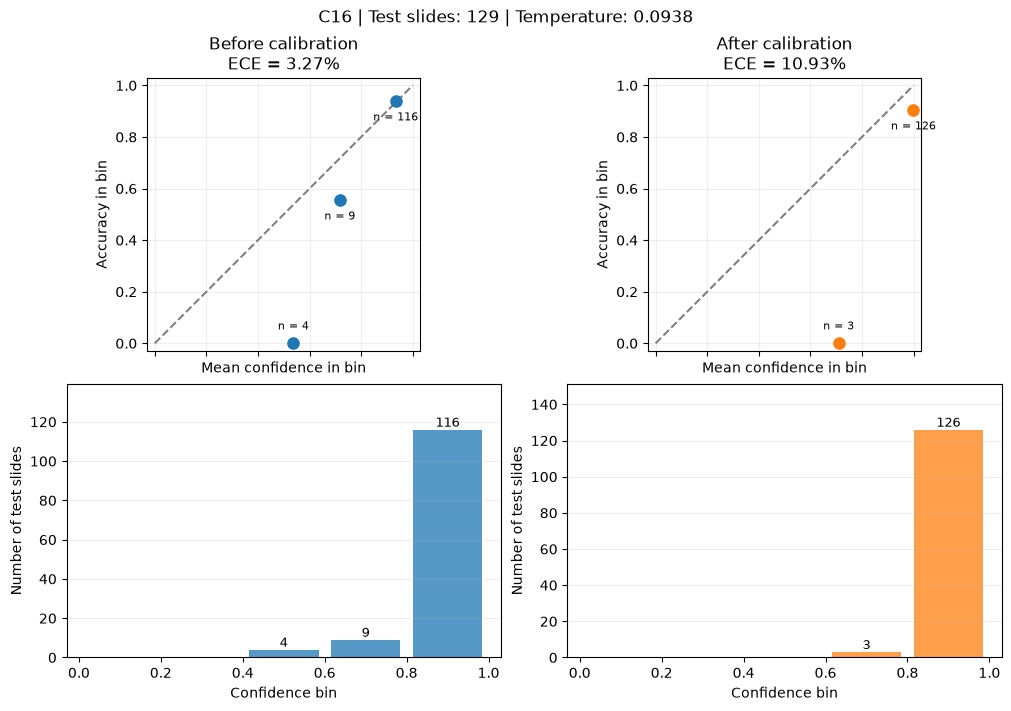

Saved: results\TemperatureScaling\C16_seed42\reliability_diagram.png


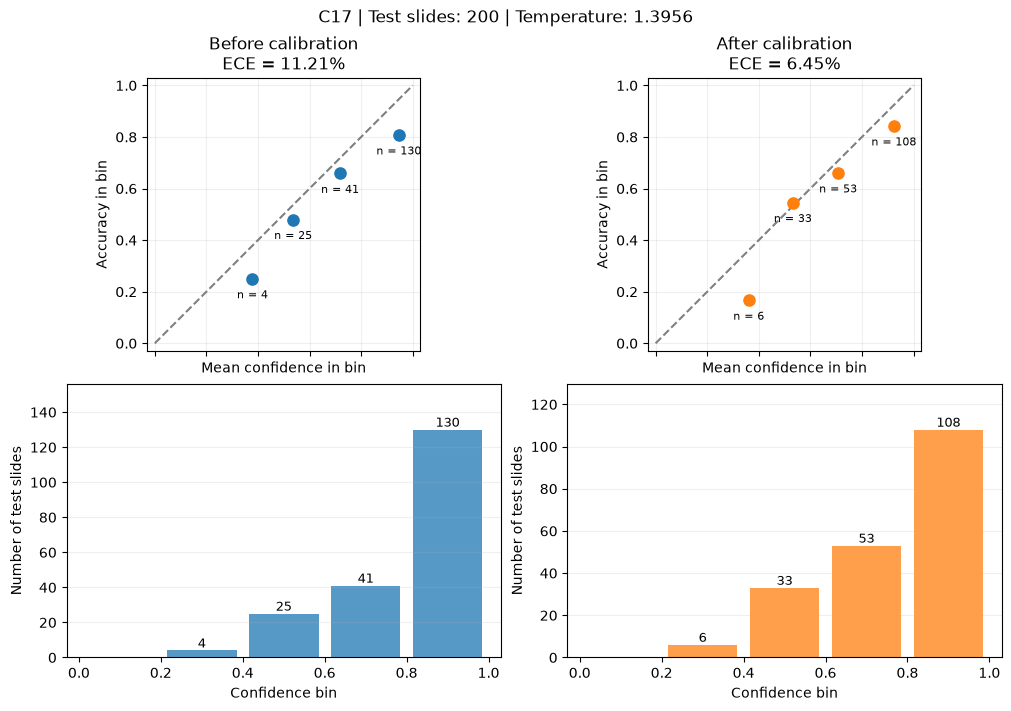

Saved: results\TemperatureScaling\C17_seed42\reliability_diagram.png


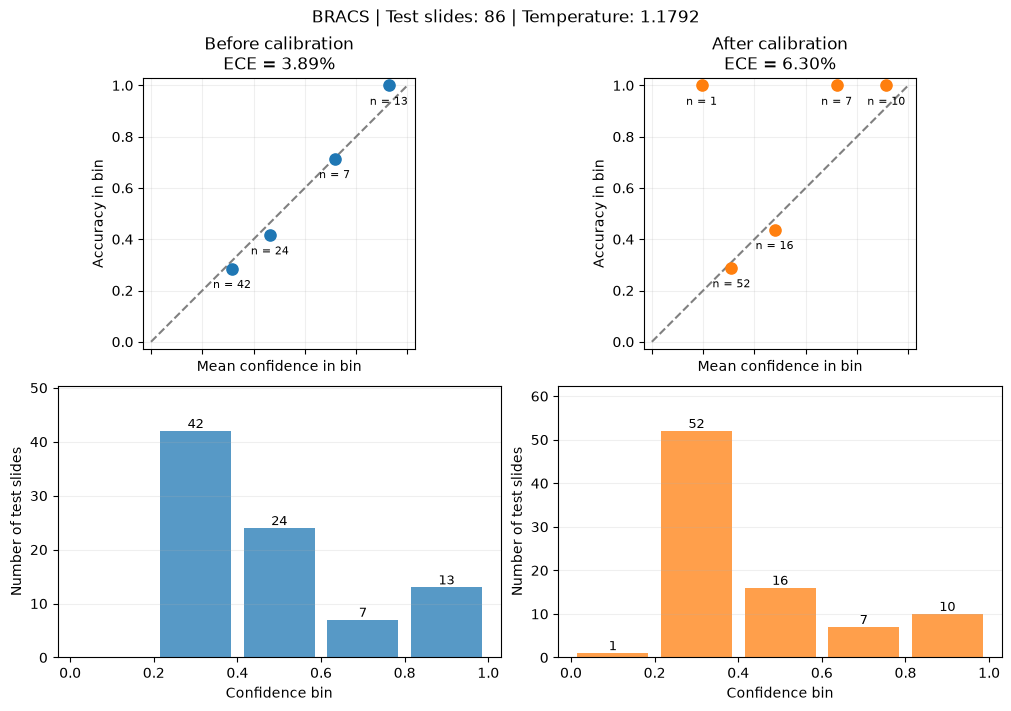

Saved: results\TemperatureScaling\BRACS_seed42\reliability_diagram.png


In [8]:
# Step 9.5 - Save reliability diagrams for all three datasets
import matplotlib.pyplot as plt

for dataset_name in ["C16", "C17", "BRACS"]:
    output_dir = (
        Path(PROJECT_DIR) / "results" / "TemperatureScaling"
        / f"{dataset_name}_seed42"
    )

    # Read the saved metrics and confidence bins
    with open(
        output_dir / "experiment.json",
        encoding = "utf-8",
    ) as f:
        experiment = json.load(f)

    bin_table = pd.read_csv(output_dir / "reliability_bins.csv")

    # Place reliability plots above confidence histograms
    fig, axes = plt.subplots(
        2, 2,
        figsize = (10, 7),
        sharex = True,
        layout = "constrained",
    )

    methods = [
        ("Uncalibrated", "before", "Before calibration", "tab:blue"),
        ("TemperatureScaling", "after", "After calibration", "tab:orange"),
    ]

    for column, (method, metric_key, title, color) in enumerate(methods):
        rows = bin_table.loc[
            bin_table["method"] == method
        ].sort_values("bin")

        # Plot observed accuracy only for bins that contain slides
        populated = rows.loc[rows["count"] > 0]

        assert int(rows["count"].sum()) == experiment["test_slides"]

        reliability_ax = axes[0, column]

        # Show perfect calibration with the diagonal line
        reliability_ax.plot(
            [0, 1], [0, 1],
            linestyle = "--",
            color = "gray",
            label = "Perfect calibration",
        )

        reliability_ax.scatter(
            populated["confidence"],
            populated["accuracy"],
            color = color,
            s = 65,
            zorder = 3,
            label = "Observed bins",
        )

        # Label each observed bin with its number of slides
        for row in populated.itertuples():
            reliability_ax.annotate(
                f"n = {int(row.count)}",
                (row.confidence, row.accuracy),
                xytext = (0, 10 if row.accuracy < 0.1 else -14),
                textcoords = "offset points",
                ha = "center",
                fontsize = 8,
            )

        ece = experiment[metric_key]["ece"]

        reliability_ax.set_title(
            f"{title}\nECE = {100 * ece:.2f}%"
        )

        reliability_ax.set_xlabel("Mean confidence in bin")
        reliability_ax.set_ylabel("Accuracy in bin")
        reliability_ax.set_xlim(-0.03, 1.03)
        reliability_ax.set_ylim(-0.03, 1.03)
        reliability_ax.set_aspect("equal", adjustable = "box")
        reliability_ax.grid(alpha = 0.2)

        # Show how many test slides fall into each confidence bin
        histogram_ax = axes[1, column]

        centers = (rows["lower"] + rows["upper"]) / 2
        widths = (rows["upper"] - rows["lower"]) * 0.85

        histogram_ax.bar(
            centers,
            rows["count"],
            width = widths,
            color = color,
            alpha = 0.75,
        )

        for center, count in zip(centers, rows["count"]):
            if count > 0:
                histogram_ax.text(
                    center,
                    count,
                    str(int(count)),
                    ha = "center",
                    va = "bottom",
                    fontsize = 9,
                )

        histogram_ax.set_xlabel("Confidence bin")
        histogram_ax.set_ylabel("Number of test slides")

        histogram_ax.set_ylim(
            0, max(1, float(rows["count"].max())) * 1.2
        )

        histogram_ax.set_xticks(np.linspace(0, 1, 6))
        histogram_ax.grid(axis = "y", alpha = 0.2)

    fig.suptitle(
        f"{dataset_name} | Test slides: {experiment['test_slides']} | "
        f"Temperature: {experiment['temperature']:.4f}"
    )

    # Save a high-resolution copy for the report
    figure_path = output_dir / "reliability_diagram.png"

    fig.savefig(
        figure_path,
        dpi = 300,
        bbox_inches = "tight",
    )

    plt.show()
    plt.close(fig)

    print("Saved:", figure_path)